# Data Preprocessing

In [16]:
!pip install PyMuPDF

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.0/20.0 MB 67.8 MB/s eta 0:00:0000:010:02

[notice] A new release of pip is available: 24.2 -> 25.0.1
[notice] To update, run: python3.12 -m pip install --upgrade pip


## Convert PDF to TxT

### Compare Extractors

In [20]:
import fitz
from tika import parser

test_file_path = "pdf_en/AbstractIntroductionMethod/The Colletotrichum boninense species complex..pdf"
parsed = parser.from_file(test_file_path)

with fitz.open(test_file_path) as doc:
    text_fitz = ""
    for page in doc:
        text_fitz += page.get_text()
with open("pdf_extracter_fitz.txt", 'w') as f:
    f.write(text_fitz)
    print("Fitz length:", len(text_fitz))
with open("pdf_extracter_tika.txt", 'w') as f:
    f.write(parsed['content'])
    print("Tika length:", len(parsed['content']))

Fitz length: 163887
Tika length: 177435


### Extract Texts - PyMuPDF

In [168]:
import os
import glob
import fitz  # PyMuPDF

pdf_dir = 'pdf_en/no_sections'
output_dir = 'pdf_en/fitz/No_sections/'

# Ensure the output directory exists
os.makedirs(output_dir, exist_ok=True)

# Get all PDF files in the directory
file_names = glob.glob(os.path.join(pdf_dir, "*.pdf"))

for pdf_path in file_names:
    pdf_name = os.path.basename(pdf_path)  # Extract filename
    text_output_path = os.path.join(output_dir, pdf_name.replace(".pdf", ".txt"))
    
    with fitz.open(pdf_path) as doc:
        text_fitz = "".join(page.get_text() for page in doc)
    
    if len(text_fitz) < 1000:
        os.remove(pdf_path)  # Remove PDF if text length is less than 100
        print(f"Removed PDF: {pdf_path} due to insufficient text length")
    else:
        with open(text_output_path, 'w', encoding='utf-8') as f:
            f.write(text_fitz)
        print(f"Extracted text saved to: {text_output_path}")

Extracted text saved to: pdf_en/fitz/No_sections/Sodium chloride, nitrogen.txt
Extracted text saved to: pdf_en/fitz/No_sections/MycoBank an online initiative to launch mycology into the 21st century..txt
Extracted text saved to: pdf_en/fitz/No_sections/First report of anthracnose fruit rot caused by Colletotrichum.txt
Extracted text saved to: pdf_en/fitz/No_sections/First Report of Anthracnose Crown Rot of Strawberry Caused by.txt
Extracted text saved to: pdf_en/fitz/No_sections/First report of anthracnose causing both crown and fruit rot of.txt
Extracted text saved to: pdf_en/fitz/No_sections/Crop pests and pathogens move polewards in a warming world..txt
Extracted text saved to: pdf_en/fitz/No_sections/COLLETOTRICHUM.txt
Extracted text saved to: pdf_en/fitz/No_sections/The United States Department.txt


### Plain text

In [171]:
import os
import glob

pdf_dir = 'pdf_en/fitz/No_sections/'
output_dir = 'pdf_en/fitz/Plain/'

# Ensure the output directory exists
os.makedirs(output_dir, exist_ok=True)

# Get all PDF files in the directory
file_names = glob.glob(os.path.join(pdf_dir, "*.txt"))

for txt_path in file_names:
    txt_name = os.path.basename(txt_path)  # Extract filename
    text_output_path = os.path.join(output_dir, txt_name)
    
    with open(txt_path, 'r', encoding='utf-8') as f:
        text = f.read()
        plain_text = ' '.join(text.split()).replace("- ", "-")    
    
    with open(text_output_path, 'w', encoding='utf-8') as f:
        f.write(plain_text)
        print(f"Plain text saved to: {text_output_path}")

Plain text saved to: pdf_en/fitz/Plain/Sodium chloride, nitrogen.txt
Plain text saved to: pdf_en/fitz/Plain/MycoBank an online initiative to launch mycology into the 21st century..txt
Plain text saved to: pdf_en/fitz/Plain/First report of anthracnose fruit rot caused by Colletotrichum.txt
Plain text saved to: pdf_en/fitz/Plain/First Report of Anthracnose Crown Rot of Strawberry Caused by.txt
Plain text saved to: pdf_en/fitz/Plain/First report of anthracnose causing both crown and fruit rot of.txt
Plain text saved to: pdf_en/fitz/Plain/Crop pests and pathogens move polewards in a warming world..txt
Plain text saved to: pdf_en/fitz/Plain/COLLETOTRICHUM.txt
Plain text saved to: pdf_en/fitz/Plain/The United States Department.txt


## Llama3.2 split length

A polyphasic approach for studying Colletotrichum.txt: Character length = 89396, Word length = 13029
An account of Colletotrichum species associated with strawberry anthracnose in China based on morphology.txt: Character length = 50034, Word length = 7366
Application of the Apn2MAT locus to improve the systematics of the Colletotrichum gloeosporioides complex.txt: Character length = 63842, Word length = 9242
Multivariate analysis methods improve the selection of strawberry.txt: Character length = 55843, Word length = 8546
Characterization and pathogenicity of Colletotrichum.txt: Character length = 47777, Word length = 7061
Colletotrichum anthracnose of Amaryllidaceae..txt: Character length = 71062, Word length = 10685
Colletotrichum species associated with anthracnose of Pyrus spp. China..txt: Character length = 135942, Word length = 21214
Colletotrichum species causing anthracnose disease of chili in China..txt: Character length = 79744, Word length = 11854
Comparison_of_Rain_Effects_

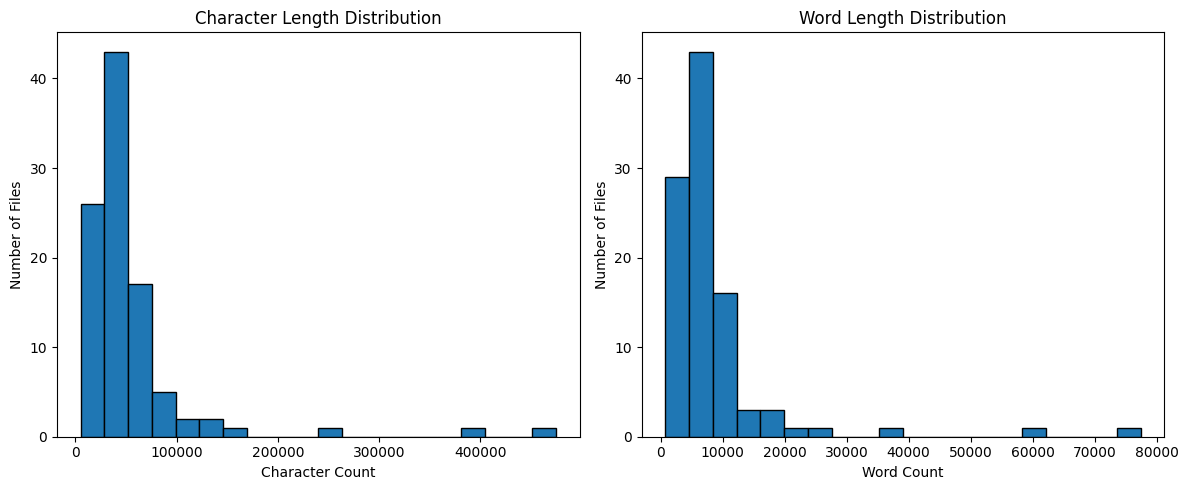

In [473]:
import os
import matplotlib.pyplot as plt

def get_file_lengths(directory):
    file_lengths = {}

    for file in os.listdir(directory):
        if file.endswith(".txt"):
            file_path = os.path.join(directory, file)
            with open(file_path, 'r', encoding='utf-8') as f:
                content = f.read()
                char_length = len(content)
                word_length = len(content.split())
                file_lengths[file] = (char_length, word_length)

    return file_lengths

def print_file_lengths(directory):
    file_lengths = get_file_lengths(directory)

    char_longest = None
    word_longest = None
    max_char_length = 0
    max_word_length = 0

    char_lengths = []
    word_lengths = []

    for file, (char_length, word_length) in file_lengths.items():
        print(f"{file}: Character length = {char_length}, Word length = {word_length}")

        char_lengths.append(char_length)
        word_lengths.append(word_length)

        if char_length > max_char_length:
            max_char_length = char_length
            char_longest = file

        if word_length > max_word_length:
            max_word_length = word_length
            word_longest = file

    print("\nSummary:")
    print(f"File with longest character length: {char_longest} ({max_char_length} characters)")
    print(f"File with longest word length: {word_longest} ({max_word_length} words)")

    # Plotting
    plt.figure(figsize=(12, 5))

    # Character length distribution
    plt.subplot(1, 2, 1)
    plt.hist(char_lengths, bins=20, edgecolor='black')
    plt.title("Character Length Distribution")
    plt.xlabel("Character Count")
    plt.ylabel("Number of Files")

    # Word length distribution
    plt.subplot(1, 2, 2)
    plt.hist(word_lengths, bins=20, edgecolor='black')
    plt.title("Word Length Distribution")
    plt.xlabel("Word Count")
    plt.ylabel("Number of Files")

    plt.tight_layout()
    plt.show()

# Example usage
directory = "pdf_en/fitz/Plain"
print_file_lengths(directory)


In [1023]:
import os
import random

# Define the directory path
directory = "pdf_en/fitz/Plain/"

# Get a list of all files in the directory
files = [f for f in os.listdir(directory) if os.path.isfile(os.path.join(directory, f))]
done_file = "paper_delimiters/done.txt"
with open(done_file, 'r') as d:
    done = [line.strip() for line in d.readlines()]
print(len(done))

# Ensure there are files to choose from
if files:
    # Randomly select a file
    random_file = random.choice(files)
    while random_file in done:
        random_file = random.choice(files)
    #random_file = "Diversity of Colletotrichum Species Associated with.txt"
    #random_file = "Influence of ammonium sulfate.txt"
    #random_file = "Colletotrichum species causing anthracnose disease of chili in China..txt"
    file_path = os.path.join(directory, random_file)
    
    # Read the content of the selected file
    with open(file_path, 'r', encoding='utf-8') as f:
        text = f.read()
        #text = ' '.join(text.split()).replace("- ", "-")
        char_length = len(text)
        word_length = len(text.split())
        print(f"{random_file}: Character length = {char_length}, Word length = {word_length}")        
        
    # Print the file name (optional)
    #print(f"Selected file: {random_file}")
    
    # Print the text content (optional)
    # print(text)
else:
    print("No files found in the directory.")

count = 0


99


KeyboardInterrupt: 

In [1018]:
import sys

sys.path.append("..")
from pcs_llama3.llama3_local import get_llm, get_tokenizer, get_sampling_params

def generate_with_loop(message, histories, llm_name="meta-llama/Llama-3.2-3B-Instruct", temperature=0.7):    
    history = []    
    # Add all chat content from both human and assistant.
    for human, assistant in histories:
        history.append({"role": "user", "content": human})
        history.append({"role": "assistant", "content": assistant})
    # Add message into the list and mark its role as user.
    history.append({"role": "user", "content": message})
    
    # =====Setting Here=====
    # Choose a version of llama3 from HuggingFace.
    llm = get_llm(llm_name, temperature)
    tokenizer = get_tokenizer()
    sampling_params = get_sampling_params(temperature = temperature)
    print(sampling_params)
    
    prompt = tokenizer.apply_chat_template(history, tokenize=False)
    
    # Keep return the newest result generated from llm.
    for chunk in llm.generate(prompt, sampling_params):
        yield chunk.outputs[0].text

#0401_after_call
prompt = f"""
Paper: 
{text} 

Extract structured information exactly as written from the provided flatten text paper and return the output in JSON format. Identify the “title”, “main section titles”, and the “first 5 words” based on the following extraction rules: 

Identify the title of the paper and exclude any author names, metadata. 
Identify the main section headings in the paper, typically formatted according to the common academic formats. "Do not" include subsections, figure or table captions. 
Include the first 5 words appearing immediately after each identified section title. Preserve original text, punctuation, and spacing. "Do not" paraphrase or modify.

Output Format (JSON):
{{
  "title": "Extracted Paper Title",
  "sections": [
    {{ "section_title": "Section Title 1", "first_words": "First 5 words..." }},
    {{ "section_title": "Section Title 2", "first_words": "First 5 words..." }},
    ...
  ]
}}
"""

temperature = 0.05
histories = []
#print(prompt)
    # Call function "generate_with_loop" to generate answer using llama3.
generated_answer = generate_with_loop(prompt, histories, temperature = temperature)
    
answer = ""
    
    # Keep update answer until the whole answer has been generated.
for ans in generated_answer:
    answer = ans
    
print(answer)
count+=1

SamplingParams(n=1, presence_penalty=0.0, frequency_penalty=0.0, repetition_penalty=1.0, temperature=0.05, top_p=0.9, top_k=-1, min_p=0.0, seed=None, stop=[], stop_token_ids=[128009, 128009], bad_words=[], include_stop_str_in_output=False, ignore_eos=False, max_tokens=4096, min_tokens=0, logprobs=None, prompt_logprobs=None, skip_special_tokens=True, spaces_between_special_tokens=True, truncate_prompt_tokens=None, guided_decoding=None)
INFO 04-13 16:06:53 metrics.py:449] Avg prompt throughput: 68.7 tokens/s, Avg generation throughput: 4.4 tokens/s, Running: 1 reqs, Swapped: 0 reqs, Pending: 0 reqs, GPU KV cache usage: 6.6%, CPU KV cache usage: 0.0%.
INFO 04-13 16:06:58 metrics.py:449] Avg prompt throughput: 3322.4 tokens/s, Avg generation throughput: 67.9 tokens/s, Running: 1 reqs, Swapped: 0 reqs, Pending: 0 reqs, GPU KV cache usage: 6.7%, CPU KV cache usage: 0.0%.
<|start_header_id|>assistant<|end_header_id|>

Here is the extracted information in JSON format:

{
  "title": "The Role o

In [1019]:
import json
import re
# Use regex to extract JSON content inside triple backticks or braces
def extract_json(llm_response):
    json_match = re.search(r"```json\n(.*?)\n```", llm_response) or \
                 re.search(r"\{.*\}", llm_response, re.DOTALL)
    
    if json_match:
        json_str = json_match.group(1) if "```json" in json_match.group(0) else json_match.group(0)
        try:
            extracted_json = json.loads(json_str)
            print("Extracted JSON:", extracted_json)
            #with open("paper_delimiters/Test/" + extracted_json['title'] + "_Lin" + str(temperature) + '_' + str(count) + ".json", "w") as json_file:
            #    json.dump(extracted_json, json_file, indent=4)
            return extracted_json
        except json.JSONDecodeError:
            print("Error: Extracted content is not valid JSON.")
    else:
        print("No JSON found in response.")
        return None
        
print(count)
section_information = extract_json(answer)

1
Extracted JSON: {'title': 'The Role of Cutinase and its Impact on Pathogenicity of Colletotrichum truncatum', 'sections': [{'section_title': 'Introduction', 'first_words': 'For successful pathogenicity, fungi employ various infection strategies to breach the host cuticle'}, {'section_title': 'Materials and Methods', 'first_words': 'Strains, culture conditions and plant materials'}, {'section_title': 'Results', 'first_words': 'Total RNA was extracted from saprophytic stage growing in CDB'}, {'section_title': 'Results', 'first_words': 'Expression analysis of cutinase gene transcript using equal amounts of RNA as the template revealed'}, {'section_title': 'Results', 'first_words': 'Phenotypic analysis of CtCut1 silenced transformants and the integration of pAA1 T-DNA with hairpin structure'}, {'section_title': 'Results', 'first_words': 'Southern blot analysis indicated that 85.7% of the fungal genomes contained the T-DNA insertion'}, {'section_title': 'Results', 'first_words': 'Soybean 

In [1020]:
import re
import json
import os

def split_text(text, section):
    section_title = re.escape(section["section_title"])
    first_words = re.escape(section["first_words"])

    matches_first_words = list(re.finditer(first_words, text, re.IGNORECASE))
    matches_section_title = list(re.finditer(section_title, text, re.IGNORECASE))

    split_index = None

    for match_first in matches_first_words:
        for match_title in matches_section_title:
            if 0 < match_first.start() - match_title.end() < 128:
                split_index = match_title.start()
                print(f"[{section['section_title']}] Match found: section_title at {match_title.start()} and first_words at {match_first.start()}")
                break
        if split_index is not None:
            break

    if split_index is None:
        if matches_first_words and ("abstract" in section_title.lower() or "introduction" in section_title.lower()):
            split_index = matches_first_words[0].start()
            print(f"[{section['section_title']}] Using first occurrence of first_words at index: {split_index}")

    if split_index is not None:
        part1, part2 = text[:split_index], text[split_index:]
        print(f"[{section['section_title']}] Splitting text at index: {split_index}")

        # Remove the section title from beginning of part2
        clean_start = re.escape(section["section_title"])
        part2 = re.sub(rf"^{clean_start}\s*", "", part2, flags=re.IGNORECASE)
        if re.match(r"^[A-Z0-9(]", part2):
            #print(True)
            return part1, part2, section["section_title"]
        else:
            #print(False)
            return None, text, None
    else:
        print(f"[{section['section_title']}] No valid split found.")
        return None, text, None



def split_into_sections(text, section_information):
    section_list = []
    sections = section_information["sections"]
    index = 0

    previous_title = None
    while index < len(sections):
        section = sections[index]
        former_text, text, current_title = split_text(text, section)

        if former_text is not None:
            # Save the previous title with the current chunk
            section_list.append({
                "title": section_information["title"],
                "section_title": previous_title,
                "content": former_text
            })            
            previous_title = current_title  # Save current title for next chunk

        index += 1

    # Append the final remaining section with the last known section title
    section_list.append({
        "title": section_information["title"],
        "section_title": previous_title or sections[-1]["section_title"],
        "content": text
    })

    return section_list



# Example usage
section_list = split_into_sections(text, section_information)

for section in section_list:
    print("Title:", section["title"])
    print("Section Title:", section["section_title"])
    preview = section["content"][:500]
    print(preview, "...")
    print("Char Length:", len(section["content"]), "   Word Length:", len(section["content"].split()))
    print("="*50)

# Save to JSON
sections_data = section_list

os.makedirs("paper_delimiters", exist_ok=True)
with open(f"paper_delimiters/{random_file[:-4]}.json", "w", encoding="utf-8") as json_file:
    json.dump(sections_data, json_file, ensure_ascii=False, indent=4)

print(f"Sections saved")


[Introduction] Match found: section_title at 275 and first_words at 288
[Introduction] Splitting text at index: 275
[Materials and Methods] Match found: section_title at 9991 and first_words at 10013
[Materials and Methods] Splitting text at index: 9991
[Results] No valid split found.
[Results] Match found: section_title at 17867 and first_words at 17950
[Results] Splitting text at index: 17867
[Results] No valid split found.
[Results] No valid split found.
[Results] No valid split found.
[Discussion] Match found: section_title at 10986 and first_words at 10997
[Discussion] Splitting text at index: 10986
Title: The Role of Cutinase and its Impact on Pathogenicity of Colletotrichum truncatum
Section Title: None
Research Article Open Access Auyong et al., J Plant Pathol Microb 2015, 6:3 DOI: 10.4172/2157-7471.1000259 Volume 6 • Isue 3 • 1000259 J Plant Pathol Microb ISSN: 2157-7471 JPPM, an open access journal Keywords: Cutinase, Pathogenicity, Colletotrichum truncatum, Anthracnose  ...


In [1021]:
import json
import re
from math import ceil

# === Load original JSON ===
with open(f"paper_delimiters/{random_file[:-4]}.json", "r", encoding="utf-8") as file:
    data = json.load(file)

MAX_WORDS = 4096

# === Helper: split long text at nearest period before max limit ===
def split_into_chunks(text, title, section_title, max_words=4096):
    words = text.split()
    total_words = len(words)

    if total_words <= max_words:
        return [{
            "title": title,
            "section_title": section_title,
            "content": text
        }]

    n_chunks = ceil(total_words / max_words)
    target_len = total_words // n_chunks

    chunks = []
    start = 0

    for i in range(n_chunks):
        if i == n_chunks - 1:
            # Last chunk gets the rest
            end = total_words
        else:
            end = min(start + target_len, total_words)
            partial_text = " ".join(words[start:end])

            # Try to end at a sentence boundary
            match = list(re.finditer(r"(?<=\w)\.(?=\s+[A-Z])", partial_text))
            if match:
                period_pos = len(partial_text[:match[-1].end()].split())
                end = start + period_pos

        chunk_words = words[start:end]
        chunk_text = " ".join(chunk_words)
        chunks.append({
            "title": title,
            "section_title": section_title,
            "content": chunk_text
        })

        start = end

    return chunks

# === Process and split ===
all_sections = []

for section in data:
    title = section["title"]
    section_title = section["section_title"]
    content = section["content"]

    #for sec in sections:
        
        #content = sec["content"]

    #if len(content.split()) > MAX_WORDS:
    chunks = split_into_chunks(content, title, section_title)
    #all_sections.extend(chunks)
    #else:    
    all_sections.extend(chunks)

# === Save output ===
with open(f"paper_delimiters/{random_file[:-4]}.json", "w", encoding="utf-8") as json_file:
    json.dump(all_sections, json_file, ensure_ascii=False, indent=4)

# === Optional: Preview chunks ===
for section in all_sections:
    print(f"Title: {section['title']}")
    print(f"Section: {section['section_title']}")
    print(section["content"][:500], "...")
    print("Char Length:", len(section["content"]), "   Word Length:", len(section["content"].split()))
    print("=" * 50)

#print("Sections saved to 'sec_test6_split.json'")


Title: The Role of Cutinase and its Impact on Pathogenicity of Colletotrichum truncatum
Section: None
Research Article Open Access Auyong et al., J Plant Pathol Microb 2015, 6:3 DOI: 10.4172/2157-7471.1000259 Volume 6 • Isue 3 • 1000259 J Plant Pathol Microb ISSN: 2157-7471 JPPM, an open access journal Keywords: Cutinase, Pathogenicity, Colletotrichum truncatum, Anthracnose  ...
Char Length: 275    Word Length: 39
Title: The Role of Cutinase and its Impact on Pathogenicity of Colletotrichum truncatum
Section: Introduction
For successful pathogenicity, fungi employ various infection strategies to breach the host cuticle. While some pathogens use mechanical means through the formation of specialised infection structures [1], others enter by direct penetration of the cuticle through the assistance of extracellular cutinase activity [2,3]. Colletotrichum truncatum, a pathogen of legumes, cereals, grasses and vegetable crops such as Capsicum species is an ascomycete that infects its host by

In [1022]:
with open("paper_delimiters/done.txt", 'a') as done_f:
    done_f.write(str(random_file) + '\n')
print(random_file, 'Done!!!')

the-role-of-cutinase-and-its-impact-on-pathogenicity-of-colletotrichum-truncatum-2157-7471-1000259.txt Done!!!


In [983]:
print(text)

Plant Disease / January 1997 77 Effects of Temperature on Sporulation and Latent Period of Colletotrichum Spp. Infecting Strawberry Fruit W. T. King, L. V. Madden, M. A. Ellis, and L. L. Wilson, Department of Plant Pathology, The Ohio State Univer-sity, Ohio Agricultural Research and Development Center, Wooster 44691 Anthracnose of strawberry (Fragaria × ananassa Duchesne) has become a major constraint on strawberry production in the United States (8,15). All strawberry plant parts can become infected and yield losses can be substantial (18). The disease is pri-marily caused by Colletotrichum acutatum J. H. Simmonds, C. gloeosporioides (Penz.) Penz. & Sacc. in Penz., and C. fra-gariae Brooks, although Gloeosporium spp., Glomerella cingulata (teleomorph of C. gloeosporioides), and C. dematium also have been shown to cause infection (1,3, 14,30,32,33). Although there has been con-siderable controversy about the taxonomy of the genus (13,31), recent isozyme and molecular evidence confirm 

In [41]:
import sys


sys.path.append("..")
from pcs_llama3.llama3_local import get_llm, get_tokenizer, get_sampling_params

def generate_with_loop(message, histories, llm_name="meta-llama/Llama-3.2-3B-Instruct", temperature=0.7):    
    history = []    
    # Add all chat content from both human and assistant.
    for human, assistant in histories:
        history.append({"role": "user", "content": human})
        history.append({"role": "assistant", "content": assistant})
    # Add message into the list and mark its role as user.
    history.append({"role": "user", "content": message})
    
    # =====Setting Here=====
    # Choose a version of llama3 from HuggingFace.
    llm = get_llm(llm_name, temperature)
    tokenizer = get_tokenizer()
    sampling_params = get_sampling_params()
    
    prompt = tokenizer.apply_chat_template(history, tokenize=False)
    
    # Keep return the newest result generated from llm.
    for chunk in llm.generate(prompt, sampling_params):
        yield chunk.outputs[0].text

prompt = f"""
The following text are sections from a paper. Please list the paper title and each section title. Below each section title, include the corresponding section content. Avoid summarizing the text; instead, focus on correcting any typos and rearranging sentences that are in the wrong order. Remove tables, figures and all in-text references (e.g., "Teng, 1994").

Title: Colletotrichum causing anthracnose disease of chili in China
TAxONOMy Based on the morphology and the multi-locus phylogeny, the 121 isolates were assigned to 15 species. Seven species (C. ae­ nigma, C. cliviae, C. endophytica, C. hymenocallidis, C. inca­ num, C. karstii, and C. viniferum) were reported from chili for the ﬁrst time. Three other species (C. fioriniae, C. fructicola, and C. scovillei) were reported for the ﬁrst time in China, and a further three species newly described. Colletotrichum conoides Y.Z. Diao, C. Zhang, L. Cai & X.L. Liu, sp. nov. — MycoBank MB812003; Fig. 7 Etymology. Referring to the host variety (Capsicum annuum var. conoides) from which the fungus was ﬁrst collected. Colonies on PDA attaining 53–55 mm diam in 4 d at 28 °C; aerial mycelia greyish white; reverse light grey to medium grey 28 Persoonia – Volume 38, 2017 Table 2c Strains used for the phylogenetic analysis of Colletotrichum species with curved conidia with details on host, location, and GenBank accession numbers. Species Isolate Host Location GenBank accession numbers ITS ACT TUB2 CHS­1 GAPDH HIS3 C. anthrisci CBS 125335 Anthriscus sylvestris Netherlands GU227846 GU227944 GU228140 GU228336 GU228238 GU228042 C. chlorophyti IMI 103806* Chlorophytum sp. India GU227894 GU227992 GU228188 GU228384 GU228286 GU228090 CBS 142.79 Stylosanthes hamata Australia GU227895 GU227993 GU228189 GU228385 GU228287 GU228091 C. circinans CBS 111.21 Allium cepa USA GU227854 GU227952 GU228148 GU228344 GU228246 GU228050 CBS 221.81* Allium cepa Serbia GU227855 GU227953 GU228149 GU228345 GU228247 GU228051 C. dematium CBS 125.25* Eryngium campestre France GU227819 GU227917 GU228113 GU228309 GU228211 GU228015 CBS 125340 Apiaceae Czech Republic GU227820 GU227918 GU228114 GU228310 GU228212 GU228016 C. fructi CBS 346.37* Malus sylvestris USA GU227844 GU227942 GU228138 GU228334 GU228236 GU228040 C. incanum ATCC 64682* Glycine max USA KC110789 KC110825 KC110816 KC110807 KC110798 IL6A Glycine max USA KC110787 KC110823 KC110814 KC110805 KC110796 IL9A Glycine max USA KC110788 KC110824 KC110815 KC110806 KC110797 CAUCT34 Capsicum sp. China KP145641 KP145505 KP145675 KP145539 KP145573 KP145607 C. lilii CBS 109214 Lilium sp. Japan GU227810 GU227908 GU228104 GU228300 GU228202 GU228006 C. lindemuthianum CBS 151.28 Lilium sp. Netherlands GU227800 GU227898 GU228094 GU228290 GU228192 GU227996 C. lineola CBS 125337* Apiaceae sp. Czech Republic GU227829 GU227927 GU228123 GU228319 GU228221 GU228025 CBS 125339 Apiaceae sp. Czech Republic GU227830 GU227928 GU228124 GU228320 GU228222 GU228026 C. liriopes CBS 119444* Lirope muscari Mexico GU227804 GU227902 GU228098 GU228294 GU228196 GU228000 CBS 122747 Lirope muscari Mexico GU227805 GU227903 GU228099 GU228295 GU228197 GU228001 C. phaseolorum 1 CBS 157.36 Phaseolus radiatus var. aureus Japan GU227896 GU227994 GU228190 GU228386 GU228288 GU228092 C. phaseolorum 2 CBS 158.36 Vigna sinensis Japan GU227897 GU227995 GU228191 GU228387 GU228289 GU228093 C. rusci CBS 119206* Ruscus sp. Italy GU227818 GU227916 GU228112 GU228308 GU228210 GU228014 C. spaethianum CBS 167.49* Hosta sieboldiana Germany GU227807 GU227905 GU228101 GU228297 GU228199 GU228003 CBS 100063 Lilium sp. South Korea GU227808 GU227906 GU228102 GU228298 GU228200 GU228004 CBS 101631 Hemerocallis sp. New Zealand GU227809 GU227907 GU228103 GU228299 GU228201 GU228005 C. spinaciae CBS 128.57 Spinacia oleracea Netherlands GU227847 GU227945 GU228141 GU228337 GU228239 GU228043 IMI 104607 Spinacia sp. Italy GU227850 GU227948 GU228144 GU228340 GU228242 GU228046 C. tofieldiae CBS 168.49 Lupinus polyphyllus Germany GU227802 GU227900 GU228096 GU228292 GU228194 GU227998 CBS 495.85 Tofieldia calyculata Switzerland GU227801 GU227899 GU228095 GU228291 GU228193 GU227997 C. trichellum CBS 118198 Hedera sp. Guatemala GU227813 GU227911 GU228107 GU228303 GU228205 GU228009 CBS 217.64 Hedera helix UK GU227812 GU227910 GU228106 GU228302 GU228204 GU228008 C. truncatum CBS 182.52 Glycine max USA GU227866 GU227964 GU228160 GU228356 GU228258 GU228062 CBS195.32 Glycine max USA GU227865 GU227963 GU228159 GU228355 GU228257 GU228061 CBS 345.70 Glycine max Denmark GU227867 GU227965 GU228161 GU228357 GU228259 GU228063 CBS 151.35* Phaseolus lunatus USA GU227862 GU227960 GU228156 GU228352 GU228254 GU228058 CAUCT1 Capsicum annuum China KP145608 KP145472 KP145642 KP145506 KP145540 KP145574 CAUCT2 Capsicum annuum China KP145609 KP145473 KP145643 KP145507 KP145541 KP145575 CAUCT3 Capsicum annuum China KP145610 KP145474 KP145644 KP145508 KP145542 KP145576 CAUCT4 Capsicum annuum China KP145611 KP145475 KP145645 KP145509 KP145543 KP145577 CAUCT5 Capsicum annuum China KP145612 KP145476 KP145646 KP145510 KP145544 KP145578 CAUCT6 Capsicum annuum China KP145613 KP145477 KP145647 KP145511 KP145545 KP145579 CAUCT7 Capsicum sp. China KP145614 KP145478 KP145648 KP145512 KP145546 KP145580 CAUCT8 Capsicum sp. China KP145615 KP145479 KP145649 KP145513 KP145547 KP145581 CAUCT9 Capsicum sp. China KP145616 KP145480 KP145650 KP145514 KP145548 KP145582 CAUCT10 Capsicum sp. China KP145617 KP145481 KP145651 KP145515 KP145549 KP145583 CAUCT11 Capsicum sp. China KP145618 KP145482 KP145652 KP145516 KP145550 KP145584 29 Y.-Z. Diao et al.: Colletotrichum causing anthracnose disease with white margin. Chlamydospores not observed. Vegetative hyphae hyaline, smooth-walled, septate, branched. Conidio­ mata and setae not observed. Conidiophores formed directly on aerial mycelium, hyaline, aseptate. Conidiogenous cells hya-line, cylindrical to clavate, 22–30 × 3.5–5 µm, opening 2.5–3 µm. Conidia hyaline, aseptate, smooth-walled, cylindrical to clavate, both ends obtusely rounded, contents granular and mostly equally distributed, 13–17.5 × 5–6.5 µm (av. = 15.9 × 5.9 µm), L/W ratio = 2.7. Appressoria single or in small groups, medium to dark brown, aseptate, mostly ellipsoidal to irregular in outline, and crenate or deeply lobed at margin, 4–11.5 × 6–10.5 µm (av. = 8.35 × 7.1 µm), L/W ratio = 1.2. Sexual morph not observed after 8 wk. Specimen examined. China, Jiangsu Province, Nanjing City, on fruits of Capsicum annuum var. conoides, Sept. 2010, Y.Z. Diao (holotype HMAS 246481, ex-type living culture CGMCC 3.17615 = CAUG17 = LC6226); ibid., NJ26, living culture CAUG33; ibid., NJ27, living culture CAUG34. Notes — Colletotrichum conoides is phylogenetically most closely related to C. hebeiense (Fig. 2). Sequence data from ITS and CHS­1 could not separate the two species, but they can be distinguished by GAPDH (12 bp), ACT (4 bp), or TUB (3 bp). The two species also differ in the following character-istics: the granules are uniformly distributed in the conidia of C. conoides but mostly present at the polar ends in the conidia of C. hebeiense; most appressoria of C. conoides are ovoid ellipsoidal with crenate or deeply lobed margin, while those of C. hebeiense are clavate to subglobose; conidia of C. conoides are slightly larger than those of C. hebeiense (13–17.5 × 5–6.5 µm vs 11.6–15.3 × 4.47–6.88 µm). In addition, C. conoides was described from Capsicum annuum var. conoides, while C. hebeiense was described from Vitis vinifera (Yan et al. 2015). A PHI test revealed no signiﬁcant recombination event between C. conoides and C. hebeiense (Fig. 8). Colletotrichum grossum Y.Z. Diao, C. Zhang, L. Cai & X.L. Liu, sp. nov. — MycoBank MB812006; Fig. 9 Etymology. Referring to the host variety (Capsicum annuum var. grossum) from which the fungus was ﬁrst collected. Colonies on PDA attaining 49–52 mm diam in 4 d at 28 °C; aerial mycelia white, reverse light grey with white margin. Chlamydospores not observed. Vegetative hyphae hyaline, smooth-walled, septate, branched. Conidiomata and setae not observed. Conidiophores formed directly on aerial mycelium, hyaline, aseptate. Conidiogenous cells hyaline, cylindrical to clavate, 22–32 × 3–3.5 µm, opening 2–2.5 µm. Conidia hyaline, aseptate, smooth-walled, cylindrical to clavate, both ends rounded or one end acute, contents granular and mostly present at the polar ends, 14.5–20.5 × 5–7.5 µm (av = 16.8 × 6.3 µm), L/W ratio = 2.7. Appressoria single, medium brown, aseptate, mostly ovoid or ellipsoidal to irregular in outline, and crenate in margin. 5.5–11.5 × 4–10.5 µm (av = 8.65 × 6.1 µm), L/W ratio = 1.4. Sexual morph not observed after 8 wk. Specimen examined. China, Hainan Province, Haikou city, on chili fruits (Capsicum annuum var. grossum), Oct. 2010, Y.Z Diao (holotype HMAS 246480, ex-type living culture CGMCC3.17614 = CAUG7 = LC6227); ibid., HN2, living culture CAUG31; ibid., HN3, living culture CAUG32. Notes — Colletotrichum grossum is phylogenetically most closely related to C. theobromicola (Fig. 2). The sequence data of ITS and CAL do not separate the two species, but they can be distinguished by GAPDH (3 bp), ACT (5 bp), and TUB (8 bp). In morphology, C. grossum differs from C. theobromicola by having wider conidia (14.5–20.5 × 5–7.5 µm vs 14.5–18.7 × 4.5–5.5 µm) and colonies that are flat white rather than black as in C. theobromicola (Rojas et al. 2010). A PHI test revealed no signiﬁcant recombination event between C. grossum and C. theobromicola (Fig. 8). C. truncatum (cont.) CAUCT12 Capsicum sp. China KP145619 KP145483 KP145653 KP145517 KP145551 KP145585 CAUCT13 Capsicum sp. China KP145620 KP145484 KP145654 KP145518 KP145552 KP145586 CAUCT14 Capsicum sp. China KP145621 KP145485 KP145655 KP145519 KP145553 KP145587 CAUCT15 Capsicum sp. China KP145622 KP145486 KP145656 KP145520 KP145554 KP145588 CAUCT16 Capsicum sp. China KP145623 KP145487 KP145657 KP145521 KP145555 KP145589 CAUCT17 Capsicum sp. China KP145624 KP145488 KP145658 KP145522 KP145556 KP145590 CAUCT18 Capsicum sp. China KP145625 KP145489 KP145659 KP145523 KP145557 KP145591 CAUCT19 Capsicum sp. China KP145626 KP145490 KP145660 KP145524 KP145558 KP145592 CAUCT20 Capsicum sp. China KP145627 KP145491 KP145661 KP145525 KP145559 KP145593 CAUCT21 Capsicum sp. China KP145628 KP145492 KP145662 KP145526 KP145560 KP145594 CAUCT22 Capsicum sp. China KP145629 KP145493 KP145663 KP145527 KP145561 KP145595 CAUCT23 Capsicum sp. China KP145630 KP145494 KP145664 KP145528 KP145562 KP145596 CAUCT24 Capsicum sp. China KP145631 KP145495 KP145665 KP145529 KP145563 KP145597 CAUCT25 Capsicum sp. China KP145632 KP145496 KP145666 KP145530 KP145564 KP145598 CAUCT26 Capsicum sp. China KP145633 KP145497 KP145667 KP145531 KP145565 KP145599 CAUCT27 Capsicum sp. China KP145634 KP145498 KP145668 KP145532 KP145566 KP145600 CAUCT28 Capsicum sp. China KP145635 KP145499 KP145669 KP145533 KP145567 KP145601 CAUCT29 Capsicum sp. China KP145636 KP145500 KP145670 KP145534 KP145568 KP145602 CAUCT30 Capsicum sp. China KP145637 KP145501 KP145671 KP145535 KP145569 KP145603 CAUCT31 Capsicum sp. China KP145638 KP145502 KP145672 KP145536 KP145570 KP145604 CAUCT32 Capsicum sp. China KP145639 KP145503 KP145673 KP145537 KP145571 KP145605 CAUCT33 Capsicum sp. China KP145640 KP145504 KP145674 KP145538 KP145572 KP145606 CAUCT33 Capsicum sp. China KP145640 KP145504 KP145674 KP145538 KP145572 KP145606 * = Ex-type culture.
"""


temperature = 0.5
histories = []
#print(prompt)
    # Call function "generate_with_loop" to generate answer using llama3.
generated_answer = generate_with_loop(prompt, histories, temperature=temperature)
    
answer = ""
    
    # Keep update answer until the whole answer has been generated.
for ans in generated_answer:
    answer = ans
    
print(answer)

INFO 03-25 01:39:51 metrics.py:449] Avg prompt throughput: 12.7 tokens/s, Avg generation throughput: 2.8 tokens/s, Running: 1 reqs, Swapped: 0 reqs, Pending: 0 reqs, GPU KV cache usage: 1.4%, CPU KV cache usage: 0.0%.
INFO 03-25 01:39:56 metrics.py:449] Avg prompt throughput: 642.6 tokens/s, Avg generation throughput: 80.5 tokens/s, Running: 1 reqs, Swapped: 0 reqs, Pending: 0 reqs, GPU KV cache usage: 1.6%, CPU KV cache usage: 0.0%.
INFO 03-25 01:40:01 metrics.py:449] Avg prompt throughput: 0.0 tokens/s, Avg generation throughput: 84.0 tokens/s, Running: 1 reqs, Swapped: 0 reqs, Pending: 0 reqs, GPU KV cache usage: 1.8%, CPU KV cache usage: 0.0%.
<|start_header_id|>assistant<|end_header_id|>

Here are the corrected section titles and content:

**Taxonomy**

Based on morphology and the multi-locus phylogeny, the 121 isolates were assigned to 15 species. Seven species (C. annigma, C. cliviae, C. endophytica, C. hymenocallidis, C. incanum, C. karstii, and C. viniferum) were reported from

## Split to Subtopic Chunks

In [1]:
import sys
import os
import json

sys.path.append("..")
from pcs_llama3.llama3_local import get_llm, get_tokenizer, get_sampling_params

def generate_with_loop(message, histories, llm_name="meta-llama/Llama-3.2-3B-Instruct", temperature=0.7):    
    history = []    
    # Add all chat content from both human and assistant.
    for human, assistant in histories:
        history.append({"role": "user", "content": human})
        history.append({"role": "assistant", "content": assistant})
    # Add message into the list and mark its role as user.
    history.append({"role": "user", "content": message})
    
    # =====Setting Here=====
    # Choose a version of llama3 from HuggingFace.
    llm = get_llm(llm_name, temperature)
    tokenizer = get_tokenizer()
    sampling_params = get_sampling_params(temperature = temperature)
    print(sampling_params)
    
    prompt = tokenizer.apply_chat_template(history, tokenize=False)
    
    # Keep return the newest result generated from llm.
    for chunk in llm.generate(prompt, sampling_params):
        yield chunk.outputs[0].text


json_dir = "sec_chao/combined/dataset_20250419.json"
output_dir = "sec_chao/llama_chunks/"
os.makedirs(output_dir, exist_ok=True)

with open(json_dir, 'r', encoding="utf-8") as f:
        data = json.load(f)
done = os.listdir(output_dir)
for entry in data:  
    if not str(entry['id']) + '.txt' in done:
        print(entry['id'])
        section = "Paper: " + entry['paper'] + " \n Section: " + entry['section_title'] + " \n " + entry['content']

    prompt = f"""
Paper: 
{section} 

Break the text above into well-structured chunks for Retrieval Augmented Generation (RAG). Each chunk should be shorter than 4096 characters, focus on a specific subtopic, and start with a clear, descriptive heading. Preserve details and ensure each chunk is coherent and self-contained. The format for each chunk should be as follows:

Chunk 1: {{topic_1}} 
{{chunk_content_1}}
Chunk 2: {{topic_2}} 
{{chunk_content_2}}
...
"""

    #temperature = 0.05
    histories = []
    #print(prompt)
        # Call function "generate_with_loop" to generate answer using llama3.
    generated_answer = generate_with_loop(prompt, histories)
    
    answer = ""
    
    # Keep update answer until the whole answer has been generated.
    for ans in generated_answer:
        answer = ans
    
    with open(output_dir + str(entry['id']) + '.txt', 'w', encoding='utf-8') as output_file:
        output_file.write(answer)

1
INFO 04-22 02:30:49 config.py:350] This model supports multiple tasks: {'generate', 'embedding'}. Defaulting to 'generate'.
WARNING 04-22 02:30:49 arg_utils.py:1013] Chunked prefill is enabled by default for models with max_model_len > 32K. Currently, chunked prefill might not work with some features or models. If you encounter any issues, please disable chunked prefill by setting --enable-chunked-prefill=False.
INFO 04-22 02:30:49 config.py:1136] Chunked prefill is enabled with max_num_batched_tokens=512.
WARNING 04-22 02:30:49 config.py:503] To see benefits of async output processing, enable CUDA graph. Since, enforce-eager is enabled, async output processor cannot be used
INFO 04-22 02:30:49 llm_engine.py:249] Initializing an LLM engine (v0.6.4.post1) with config: model='meta-llama/Llama-3.2-3B-Instruct', speculative_config=None, tokenizer='meta-llama/Llama-3.2-3B-Instruct', skip_tokenizer_init=False, tokenizer_mode=auto, revision=None, override_neuron_config=None, tokenizer_revis

Loading safetensors checkpoint shards:   0% Completed | 0/2 [00:00<?, ?it/s]


INFO 04-22 02:30:53 model_runner.py:1077] Loading model weights took 6.0160 GB
INFO 04-22 02:30:53 worker.py:232] Memory profiling results: total_gpu_memory=39.38GiB initial_memory_usage=6.54GiB peak_torch_memory=7.19GiB memory_usage_post_profile=6.55GiB non_torch_memory=0.53GiB kv_cache_size=27.72GiB gpu_memory_utilization=0.90
INFO 04-22 02:30:53 gpu_executor.py:113] # GPU blocks: 16221, # CPU blocks: 2340
INFO 04-22 02:30:53 gpu_executor.py:117] Maximum concurrency for 131072 tokens per request: 1.98x
SamplingParams(n=1, presence_penalty=0.0, frequency_penalty=0.0, repetition_penalty=1.0, temperature=0.7, top_p=0.9, top_k=-1, min_p=0.0, seed=None, stop=[], stop_token_ids=[128009, 128009], bad_words=[], include_stop_str_in_output=False, ignore_eos=False, max_tokens=4096, min_tokens=0, logprobs=None, prompt_logprobs=None, skip_special_tokens=True, spaces_between_special_tokens=True, truncate_prompt_tokens=None, guided_decoding=None)
INFO 04-22 02:31:02 metrics.py:449] Avg prompt throu

KeyboardInterrupt: 

In [60]:
import sys


sys.path.append("..")
from pcs_llama3.llama3_local import get_llm, get_tokenizer, get_sampling_params

def generate_with_loop(message, histories, llm_name="meta-llama/Llama-3.2-3B-Instruct", temperature=0.7):    
    history = []    
    # Add all chat content from both human and assistant.
    for human, assistant in histories:
        history.append({"role": "user", "content": human})
        history.append({"role": "assistant", "content": assistant})
    # Add message into the list and mark its role as user.
    history.append({"role": "user", "content": message})
    
    # =====Setting Here=====
    # Choose a version of llama3 from HuggingFace.
    llm = get_llm(llm_name, temperature)
    tokenizer = get_tokenizer()
    sampling_params = get_sampling_params()
    
    prompt = tokenizer.apply_chat_template(history, tokenize=False)
    
    # Keep return the newest result generated from llm.
    for chunk in llm.generate(prompt, sampling_params):
        yield chunk.outputs[0].text

prompt = f"""
Please break the following text into well-structured chunks for Retrieval Augmented Generation (RAG). Each chunk should consist of 100 to 200 words and focus on a specific subtopic. At the beginning of each chunk, clearly label the corresponding topic. Ensure that each chunk is a complete, coherent unit of information, maintaining clarity and readability throughout. No details from the original text should be omitted.
The format for each chunk should be as follows:
Chunk {{i}}: {{topic}} 
{{chunk content}}

TAXONOMY
Based on the morphology and multi-locus phylogeny, the 121 isolates were assigned to 15 species. Seven species (C. ae¬ nigma, C. cliviae, C. endophytica, C. hymenocallidis, C. inca¬ num, C. karstii, and C. viniferum) were reported from chili for the first time. Three other species (C. fioriniae, C. fructicola, and C. scovillei) were reported for the first time in China, and a further three species were newly described.
Colletotrichum conoides Y.Z. Diao, C. Zhang, L. Cai & X.L. Liu, sp. nov. — MycoBank MB812003
Etymology: Referring to the host variety (Capsicum annuum var. conoides) from which the fungus was first collected.
Colonies on PDA attaining 53–55 mm diam in 4 d at 28 °C; aerial mycelia greyish white; reverse light grey to medium grey. Chlamydospores not observed. Vegetative hyphae hyaline, smooth-walled, septate, branched. Conidiomata and setae not observed. Conidiophores formed directly on aerial mycelium, hyaline, aseptate. Conidiogenous cells hyaline, cylindrical to clavate, 22–30 × 3.5–5 µm, opening 2.5–3 µm. Conidia hyaline, aseptate, smooth-walled, cylindrical to clavate, both ends obtusely rounded, contents granular and mostly equally distributed, 13–17.5 × 5–6.5 µm (avg = 15.9 × 5.9 µm), L/W ratio = 2.7. Appressoria single or in small groups, medium to dark brown, aseptate, mostly ellipsoidal to irregular in outline, and crenate or deeply lobed at the margin, 4–11.5 × 6–10.5 µm (avg = 8.35 × 7.1 µm), L/W ratio = 1.2. Sexual morph not observed after 8 wk.
Specimen examined: China, Jiangsu Province, Nanjing City, on fruits of Capsicum annuum var. conoides, Sept. 2010, Y.Z. Diao (holotype HMAS 246481, ex-type living culture CGMCC 3.17615 = CAUG17 = LC6226); ibid., NJ26, living culture CAUG33; ibid., NJ27, living culture CAUG34.
Notes: Colletotrichum conoides is phylogenetically most closely related to C. hebeiense. Sequence data from ITS and CHS¬1 could not separate the two species, but they can be distinguished by GAPDH (12 bp), ACT (4 bp), or TUB (3 bp). The two species also differ in the following characteristics: the granules are uniformly distributed in the conidia of C. conoides but mostly present at the polar ends in the conidia of C. hebeiense; most appressoria of C. conoides are ovoid ellipsoidal with crenate or deeply lobed margin, while those of C. hebeiense are clavate to subglobose; conidia of C. conoides are slightly larger than those of C. hebeiense (13–17.5 × 5–6.5 µm vs. 11.6–15.3 × 4.47–6.88 µm). In addition, C. conoides was described from Capsicum annuum var. conoides, while C. hebeiense was described from Vitis vinifera. A PHI test revealed no significant recombination event between C. conoides and C. hebeiense.
Colletotrichum grossum Y.Z. Diao, C. Zhang, L. Cai & X.L. Liu, sp. nov. — MycoBank MB812006
Etymology: Referring to the host variety (Capsicum annuum var. grossum) from which the fungus was first collected.
Colonies on PDA attaining 49–52 mm diam in 4 d at 28 °C; aerial mycelia white, reverse light grey with white margin. Chlamydospores not observed. Vegetative hyphae hyaline, smooth-walled, septate, branched. Conidiomata and setae not observed. Conidiophores formed directly on aerial mycelium, hyaline, aseptate. Conidiogenous cells hyaline, cylindrical to clavate, 22–32 × 3–3.5 µm, opening 2–2.5 µm. Conidia hyaline, aseptate, smooth-walled, cylindrical to clavate, both ends rounded or one end acute, contents granular and mostly present at the polar ends, 14.5–20.5 × 5–7.5 µm (avg = 16.8 × 6.3 µm), L/W ratio = 2.7. Appressoria single, medium brown, aseptate, mostly ovoid or ellipsoidal to irregular in outline, and crenate in margin. 5.5–11.5 × 4–10.5 µm (avg = 8.65 × 6.1 µm), L/W ratio = 1.4. Sexual morph not observed after 8 wk.
Specimen examined: China, Hainan Province, Haikou City, on chili fruits (Capsicum annuum var. grossum), Oct. 2010, Y.Z Diao (holotype HMAS 246480, ex-type living culture CGMCC3.17614 = CAUG7 = LC6227); ibid., HN2, living culture CAUG31; ibid., HN3, living culture CAUG32.
Notes: Colletotrichum grossum is phylogenetically most closely related to C. theobromicola. The sequence data of ITS and CAL do not separate the two species, but they can be distinguished by GAPDH (3 bp), ACT (5 bp), and TUB (8 bp). In morphology, C. grossum differs from C. theobromicola by having wider conidia (14.5–20.5 × 5–7.5 µm vs. 14.5–18.7 × 4.5–5.5 µm) and colonies that are flat white rather than black as in C. theobromicola. A PHI test revealed no significant recombination event between C. grossum and C. theobromicola.
"""

#temperature = 0.1
histories = []
#print(prompt)
    # Call function "generate_with_loop" to generate answer using llama3.
generated_answer = generate_with_loop(prompt, histories)
    
answer = ""
    
    # Keep update answer until the whole answer has been generated.
for ans in generated_answer:
    answer = ans
    
print(answer)

SyntaxError: invalid character '—' (U+2014) (1264367767.py, line 72)

In [612]:
ttt = """
```
{
  "title": "Influence of Ammonium Sulfate and Rotation Crops on Strawberry Black Root Rot",
  "sections": [
    {
      "section_title": "Plant Disease",
      "first_words": "Plant Disease / February"
    },
    {
      "section_title": "Materials and Methods",
      "first_words": "Plot establishment"
    },    
    {
      "section_title": "Discussion",
      "first_words": "Combining Saia oats"
    },
    {
      "section_title": "Acknowledgments",
      "first_words": "We thank E."
    },
    {
      "section_title": "Literature Cited",
      "first_words": "Barker, K. R."
    }
  ]
}
```"""


def extract_json(llm_response):
    json_match = re.search(r"```json\n(.*?)\n```", llm_response) or \
                 re.search(r"\{.*\}", llm_response, re.DOTALL)
    
    if json_match:
        json_str = json_match.group(1) if "```json" in json_match.group(0) else json_match.group(0)
        try:
            extracted_json = json.loads(json_str)
            print("Extracted JSON:", extracted_json)
            return extracted_json
        except json.JSONDecodeError:
            print("Error: Extracted content is not valid JSON.")
    else:
        print("No JSON found in response.")
        return None

section_information = extract_json(ttt)
print(ttt)

Extracted JSON: {'title': 'Colletotrichum causing anthracnose disease of chili in China', 'sections': [{'section_title': 'INTRODUCTION', 'first_words': 'Chili (Capsicum spp.) is an important vegetable crop worldwide.'}, {'section_title': 'MATERIALS AND METHODS', 'first_words': 'From 2008 to 2014, fruits and leaves of chili (Capsicum spp.) with anthracnose symptoms'}, {'section_title': 'RESULTS', 'first_words': 'Disease survey and strain isolation Symptoms of anthracnose were circular'}, {'section_title': 'TAXONOMY', 'first_words': 'Based on the morphology and the multi-locus phylogeny, the 121 isolates were assigned'}, {'section_title': 'DISCUSSION', 'first_words': 'Colletotrichum truncatum, the most frequently isolated species in this study, has been'}, {'section_title': 'REFERENCES', 'first_words': 'Alaniz S, Hernández L, Mondino P. 2015.'}]}

```
{
  "title": "Colletotrichum causing anthracnose disease of chili in China",
  "sections": [
    {
      "section_title": "INTRODUCTION",


In [ ]:
#0401_after_call
prompt = f"""
Paper: 
{text} 

Extract structured information exactly as written from the provided flatten text paper and return the output in JSON format. Identify the “title”, “main section titles”, and the “first 5 words” based on the following extraction rules: 

Identify the title of the paper and exclude any author names, metadata. 
Identify the main section headings in the paper, typically formatted according to the IMRaD structure or other common academic formats. "Do not" include subsections, figure or table captions. 
Include the first 5 words appearing immediately after each identified section title. Preserve original text, punctuation, and spacing. "Do not" paraphrase or modify.

Output Format (JSON):
{{
  "title": "Extracted Paper Title",
  "sections": [
    {{ "section_title": "Section Title 1", "first_words": "First 5 words..." }},
    {{ "section_title": "Section Title 2", "first_words": "First 5 words..." }},
    ...
  ]
}}
"""


In [ ]:
#Lin0401
prompt = f"""
Paper: 
{text} 

Extract structured information exactly as written from the provided flatten text paper and return the output in JSON format. Identify the “title”, “main section titles”, and the “first 5 words” based on following rules: 

Identify the title of the paper and exclude any author names, metadata. 
Identify the main section headings in the paper, typically formatted according to the IMRaD structure or other common academic formats. “Do not” include subsections, figure or table captions. 
Include the first 5 words appearing immediately after each identified section title. Preserve original text, punctuation, and spacing. “Do not” paraphrase or modify.

Output Format (JSON):
{{
  "title": "Extracted Paper Title",
  "sections": [
    {{ "section_title": "Section Title 1", "first_words": "First 5 words..." }},
    {{ "section_title": "Section Title 2", "first_words": "First 5 words..." }},
    ...
  ]
}}
"""


In [ ]:
#0401
prompt = f"""
Paper:
{text}

Extract structured information exactly as written from the provided flatten text paper and return the output in JSON format. Identify the **title**, **main section titles**, and the **first 5 words** based on following rules. Extraction Rules:

Title Identification: Identify the title of the paper and exclude any author names, metadata.
Section Title Identification: Identify the main section headings in the paper, typically formatted according to the IMRaD structure or other common academic formats. Do not include subsections, figure or table captions.
Extracting First 5 Words: Include the first 5 words appearing immediately after each identified section title. Preserve original text, punctuation, and spacing. Do not paraphrase or modify. 

Output Format (JSON):
{{
  "title": "Extracted Paper Title",
  "sections": [
    {{ "section_title": "Section Title 1", "first_words": "First 5 words..." }},
    {{ "section_title": "Section Title 2", "first_words": "First 5 words..." }},
    ...
  ]
}}
"""

In [ ]:
#Lin 0326
prompt = f"""
Paper:
{text}

Extract structured information exactly as written from the provided flatten text paper and return the output in JSON format. Identify the **title**, **main section titles**, and the **first 5 words** based on following rules. Extraction Rules:

Title Identification: Identify the title of the paper and exclude any author names, metadata.
Section Title Identification: Identify the main section headings in the paper, typically formatted according to the IMRaD structure or other common academic formats. **Do not** include subsections, figure or table captions.
Extracting First 5 Words: Include the first 5 words appearing immediately after each identified section title. Preserve original text, punctuation, and spacing. **Do not** paraphrase or modify. 

Output Format (JSON):
{{
  "title": "Extracted Paper Title",
  "sections": [
    {{ "section_title": "Section Title 1", "first_words": "First 5 words..." }},
    {{ "section_title": "Section Title 2", "first_words": "First 5 words..." }},
    ...
  ]
}}
"""

In [ ]:
#0326
prompt = f"""
Paper:
{text}

Extract structured information exactly as written from the provided flatten text paper and return the output in JSON format. Identify the **title**, **main section titles**, and the **first 5 words** based on following rules.

Extraction Rules:
1. Title Identification: Identify the title of the paper and exclude any author names, metadata.
2. Section Title Identification: Identify the main section headings in a research paper, typically formatted according to the IMRAD structure or other common academic formats. Section headings may appear in ALL CAPS, Title Case, or written as content-specific or summary-style. **Do NOT** include subsections, figure or table captions.
3. Extracting First 5 Words: Include the first 5 words appearing immediately after each identified section title. Preserve original text, punctuation, and spacing. **Do not** paraphrase or modify.   

Output Format (JSON):
{{
  "title": "Extracted Paper Title",
  "sections": [
    {{ "section_title": "Section Title 1", "first_words": "First 5 words..." }},
    {{ "section_title": "Section Title 2", "first_words": "First 5 words..." }},
    ...
  ]
}}
"""

In [ ]:
#Lin's Prompt
prompt = f"""
Paper:
{text}

Extract structured information exactly as written from the provided flatten text paper and return the output in JSON format. Identify the **title**, **main section titles**, and the **first 5 words** based on following rules.

Extraction Rules:
1. Title Identification: Identify the title of the paper and exclude any author names, metadata.
2. Section Title Identification: Identify section headings formatted in IMRaD or other paper formats.
3. Extracting First 5 Words: Include the first 5 words appearing immediately after each identified section title. Preserve original text, punctuation, and spacing. Do not paraphrase or modify.   

### Output Format (JSON):
{{
  "title": "Extracted Paper Title",
  "sections": [
    {{ "section_title": "Section Title 1", "first_words": "First 5 words..." }},
    {{ "section_title": "Section Title 2", "first_words": "First 5 words..." }},
    ...
  ]
}}
"""

In [ ]:
#General Paper
prompt = f"""
Original Paper:
{text}

Extract structured information exactly as written from the provided flatten text paper and return the output in JSON format.

Instructions:
1. Identify the **title**, **main section titles**, and the **first 5 words** immediately following each section title.
2. Follow the rules below to ensure accuracy and consistency.

Extraction Rules:
1. Title Identification:
   - Extract the title of the paper.
   - Exclude any author names, metadata.

2. Section Title Detection:
   - Identify section headings formatted in **ALL CAPS, title case or phrase-like summaries**.
   - Section titles may contain numbers (e.g., `"1. Section Title"` or `"III. Section Title"`).   
   - Each section title only appears one time.
   - **Do not** extract **figure, table title** and **subsection title**.
   - Ensure section titles are extracted exactly as written in the text.

3. Extracting First 5 Words:
   - Capture the first 5 words appearing **immediately after** each detected section title.
   - Preserve **original text, punctuation, and spacing**—do not paraphrase or modify.
   - If a subsection title appears within the first 5 words after a section title, **include it as part of the first 5 words**.
   

### Output Format (JSON):
{{
  "title": "Extracted Paper Title",
  "sections": [
    {{ "section_title": "Section Title 1", "first_words": "First 5 words..." }},
    {{ "section_title": "Section Title 2", "first_words": "First 5 words..." }},
    ...
  ]
}}
"""

In [ ]:
#General Paper
prompt = f"""
Original Paper:
{text}

Extract structured information exactly as written from the provided flatten text paper and return the output in JSON format.

Instructions:
1. Identify the **title**, **main section titles**, and the **first 5 words** immediately following each section title.
2. Follow the rules below to ensure accuracy and consistency.

Extraction Rules:
1. Title Identification:
   - Extract the title of the paper.
   - Exclude any author names, metadata.

2. Section Title Detection:
   - Identify section headings formatted in **ALL CAPS, title case or phrase-like summaries**.
   - Section titles may contain numbers (e.g., `"1. Section Title"` or `"III. Section Title"`).
   - If a subsection title appears within the first 5 words after a section title, **include it as part of the first 5 words**.
   - Each section title only appears one time.
   - **Do not** extract **figure, table title** and **subsection title**.

3. Extracting First 5 Words**:
   - Capture the first 5 words appearing **immediately after** each detected section title.
   - Preserve **original text, punctuation, and spacing**—do not paraphrase or modify.
   - Ensure section titles are extracted exactly as written in the text.

### Output Format (JSON):
{{
  "title": "Extracted Paper Title",
  "sections": [
    {{ "section_title": "Section Title 1", "first_words": "First 5 words..." }},
    {{ "section_title": "Section Title 2", "first_words": "First 5 words..." }},
    ...
  ]
}}
"""

In [ ]:
#Research Paper Prompt
prompt = f"""
### Original Paper:
{text}

Extract structured information exactly as written from a plain text original research paper.


Extract and preserve the exact wording. Identify the **title** and **main sections** of the research paper.
Sections should follow a **typical research paper structure** but are not limited to: Abstract, Introduction, Meterials and Methods, Results, Discussion, etc. Some of the above may have differences in spelling. Please refer to the text in the original version.  
How to Identify Section Titles: Section titles are usually in **all caps, title case, or bold. Some variations may include numbers (e.g., "1. INTRODUCTION" or "III. RESULTS"). Section titles should be case-insensitive (e.g., "Introduction", "INTRODUCTION", and "introduction" are equivalent). If a **subsection title appears within the first 5 words**, **do not omit it**; extract it as part of the first 5 words.

Extraction Rules:
- **Capture the first 5 words** after each detected section title.
- Ensure section titles appear as written in the text.
- Preserve **original text, punctuation, and spacing**—no paraphrasing.

### Output Format (JSON)
{{
  "title": "...",
  "sections": [
    {{ "section_title": "...", "first_words": "..." }},
    {{ "section_title": "...", "first_words": "..." }},
    ...
  ]
}}
"""

In [ ]:
#old version prompt
prompt = f"""
### Original Paper:
{text}

Extract structured information exactly as written from a plain text original research paper.

### Instructions
- Extract and preserve the exact wording.
- Identify the **title** and **main sections** of the research paper.
- Sections should follow a **typical research paper structure** but are not limited to:
  - Abstract, Introduction, Meterials and Methods, Results, Discussion, etc.
  - Some of the above may have differences in spelling. Please refer to the text in the original version.  
- **How to Identify Section Titles:**
  - Section titles are usually in **all caps, title case, or bold.**
  - Some variations may include numbers (e.g., "1. INTRODUCTION" or "III. RESULTS").
  - Section titles should be case-insensitive (e.g., "Introduction", "INTRODUCTION", and "introduction" are equivalent).
  - If a **subsection title appears within the first 5 words**, **do not omit it**; extract it as part of the first 5 words.

### Extraction Rules:
- **Capture the first 5 words** after each detected section title.
- Ensure section titles appear as written in the text.
- Preserve **original text, punctuation, and spacing**—no paraphrasing.

### Output Format (JSON)
{{
  "title": "...",
  "sections": [
    {{ "section_title": "...", "first_words": "..." }},
    {{ "section_title": "...", "first_words": "..." }},
    ...
  ]
}}
"""

In [ ]:
#old version prompt
prompt = f"""
Extract structured information exactly as written from a plain text original research paper.

### Instructions
- Extract and preserve the exact wording.
- Identify the **title** and **main sections** of the research paper.
- Sections should follow a **typical research paper structure** but are not limited to:
  - ABSTRACT
  - INTRODUCTION
  - MATERIALS AND METHODS / METHODOLOGY
  - RESULTS
  - DISCUSSION
  - CONCLUSION / SUMMARY
  - ACKNOWLEDGMENTS
  - REFERENCES / LITERATURE CITED
- **How to Identify Section Titles:**
  - Section titles are usually in **all caps, title case, or bold.**
  - They often appear **on a separate line** with spacing before and after.
  - Some variations may include numbers (e.g., "1. INTRODUCTION" or "III. RESULTS").
  - Section titles should be case-insensitive (e.g., "Introduction", "INTRODUCTION", and "introduction" are equivalent).
  - If a **subsection title appears within the first 5 words**, **do not omit it**; extract it as part of the first 5 words.

### Extraction Rules:
- **Capture the first five words** after each detected section title.
- Ensure section titles appear as written in the text.
- Preserve **original text, punctuation, and spacing**—no paraphrasing.

### Output Format (JSON)
{{
  "title": "...",
  "sections": [
    {{ "section_title": "...", "first_words": "..." }},
    {{ "section_title": "...", "first_words": "..." }},
    ...
  ]
}}

### Input
{text}
"""

In [785]:
file_path = 'pdf_en/fitz/Plain/Lifestyles of Colletotrichum acutatum..txt'

# Read the original content
with open(file_path, 'r', encoding='utf-8') as file:
    content = file.read()

# Remove all hyphens
content_no_hyphens = content.replace('-', '')

# Write the cleaned content back to the same file (or change the path to save to a new file)
with open(file_path, 'w', encoding='utf-8') as file:
    file.write(content_no_hyphens)

print("Hyphens removed successfully.")

Hyphens removed successfully.
